# P2A burn and the 31.0.0 fleet: daily charts

Draws two charts from a node's debug.logs:

1. **Reconstruction, suspicious agents and rejections per day**
2. **Messages received per day and peer group**

`scripts/run_all.sh` turns the logs into the CSVs in `data/` (the README lists the node settings it needs); this
notebook only reads them. The files in the repo come from our node, Jul 8 to Oct 23 (cut at Oct 24 00:00 UTC);
put your node's files in `data/` to draw its charts.

- `data/daily_metrics.csv`: per day, the compact blocks reconstructed, the share of them that needed no tx
  requests, and the txs rejected for missing or spent inputs.
- `data/full_daily_msgs.csv`: messages received per day and peer group, each peer tied to the user agent and
  protocol of its version message.
- `data/events.csv`: when each group arrives and stops, drawn as dashed lines.

Peer groups (user agent and protocol only, tx contents play no part):

| group | rule |
|---|---|
| p2aburn | user agent starts with `/p2aburn` |
| txbroadcast | user agent starts with `/txbroadcast` |
| fleet | `/Sat0shi:31.0.0/`, or `/Satoshi:31.0.0/` with protocol 70015 |
| other | everyone else |
| unknown | peers whose version message is in no log (connected before the first one); drawn with other |

In [1]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd

DATA = Path('data')

## 1. Load

A group arrives with its first version message, and stops with the last message one of its peers sent us if
that is more than a day before the end of the data; a group still active then has no stop.

In [2]:
metrics = pd.read_csv(DATA / 'daily_metrics.csv', parse_dates=['day'])
msgs = pd.read_csv(DATA / 'full_daily_msgs.csv', parse_dates=['day'])
events = pd.read_csv(DATA / 'events.csv', parse_dates=['time'])
events = [(time.tz_localize(None), group, label) for time, group, label in events.itertuples(index=False)]
print(f'daily_metrics: {len(metrics)} days, {metrics.day.min():%b %-d} to {metrics.day.max():%b %-d}')
print(f'full_daily_msgs: {msgs.day.nunique()} days, {msgs.day.min():%b %-d} to {msgs.day.max():%b %-d}')
for time, _, label in events:
    print(f'{time:%b %-d %H:%M}  {label}')

# new and active connections per group, empty on days with no logs
conn = msgs.pivot_table(index='day', columns='group', values=['new_connections', 'distinct_peers'], aggfunc='sum')
panels = metrics[['day', 'reconstruction_no_request_share', 'rejected_inputs_missing']].set_index('day')
# days without logs stay empty in the charts instead of being bridged
panels = panels.reindex(pd.date_range(panels.index.min(), panels.index.max(), name='day'))
for g in ['txbroadcast', 'fleet', 'p2aburn']:
    panels[f'{g}_new'] = conn[('new_connections', g)].reindex(panels.index)
    panels[f'{g}_active'] = conn[('distinct_peers', g)].reindex(panels.index)
# a sample of the table the first chart draws
panels.tail(7)

daily_metrics: 108 days, Jul 8 to Oct 23
full_daily_msgs: 108 days, Jul 8 to Oct 23
Jul 25 20:21  txbroadcast stops
Jul 28 14:17  fleet arrives
Oct 18 13:28  fleet stops


,reconstruction_no_request_share,rejected_inputs_missing,txbroadcast_new,txbroadcast_active,fleet_new,fleet_active,p2aburn_new,p2aburn_active
day,,,,,,,,
2026-10-17,0.0148,2457866,0.0,0.0,979.0,987.0,2962.0,2966.0
2026-10-18,0.2710,1059244,0.0,0.0,367.0,375.0,1435.0,1439.0
2026-10-19,0.6104,18870,0.0,0.0,0.0,0.0,34.0,34.0
2026-10-20,0.5976,43339,0.0,0.0,0.0,0.0,52.0,55.0
2026-10-21,0.7086,36850,0.0,0.0,0.0,0.0,40.0,43.0
2026-10-22,0.6250,23776,0.0,0.0,0.0,0.0,26.0,30.0
2026-10-23,0.6494,130080,0.0,0.0,0.0,0.0,50.0,53.0


## 2. Chart style

Each peer group keeps one color in both charts; the reconstruction line is neutral so no group color means two things. Each panel keeps its own y scale; all share the date axis.

In [3]:
COLORS = {
    'share': '#3d3c38',
    'missing': '#eda100',
    'p2aburn': '#2a78d6',
    'fleet': '#eb6834',
    'txbroadcast': '#1baf7a',
    'other': '#8a8a85',
}
LABELS = {
    'p2aburn': 'p2aburn (/p2aburn*)',
    'fleet': 'fleet (31.0.0/70015)',
    'txbroadcast': 'txbroadcast (/txbroadcast*)',
    'other': 'other peers',
}
INK, MUTED, GRID, AXIS = '#1f1e1d', '#6b6a64', '#e6e5e0', '#a9a8a2'
ONE_DAY = pd.Timedelta(days=1)

plt.rcParams.update({
    'font.size': 9, 'axes.titlesize': 9, 'axes.titlelocation': 'left', 'axes.titlecolor': INK,
    'axes.edgecolor': AXIS, 'axes.labelcolor': MUTED, 'xtick.color': MUTED, 'ytick.color': MUTED,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.spines.left': False,
    'axes.grid': True, 'axes.grid.axis': 'y', 'grid.color': GRID, 'grid.linewidth': 0.8,
    'ytick.left': False, 'figure.dpi': 110, 'hatch.linewidth': 1.0,
})


def compact(v, _=None):
    for div, suffix in ((1e9, 'B'), (1e6, 'M'), (1e3, 'K')):
        if abs(v) >= div:
            return f'{v / div:.1f}'.rstrip('0').rstrip('.') + suffix
    return f'{v:g}'


def percent(v, _=None):
    return f'{v:.0%}'


def style_axis(ax, x0, x1, fmt=compact):
    ax.set_xlim(x0, x1)
    ax.set_ylim(bottom=0)
    ax.yaxis.set_major_locator(plt.MaxNLocator(3))
    ax.yaxis.set_major_formatter(fmt)
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %-d'))
    ax.set_axisbelow(True)
    for t, group, _ in events:
        if x0 <= t <= x1:
            ax.axvline(t, color=COLORS[group], lw=1.1, ls=(0, (4, 3)), zorder=0)


def panel_figure(n, height):
    """A strip for the event labels above n panels sharing the date axis."""
    fig, axes = plt.subplots(n + 1, 1, figsize=(12, height), sharex=True,
                             gridspec_kw={'hspace': 0.45, 'height_ratios': [0.55] + [1] * n})
    strip = axes[0]
    strip.axis('off')
    return fig, strip, axes[1:]


def label_events(strip, x0, x1):
    """One row per event, earliest at the top, each label beside its line."""
    shown = [(t, group, label) for t, group, label in events if x0 <= t <= x1]
    strip.set_ylim(0, len(shown) or 1)
    for i, (t, group, label) in enumerate(shown):
        row = len(shown) - 1 - i
        strip.vlines(t, 0, row + 0.5, color=COLORS[group], lw=1.1, ls=(0, (4, 3)))
        # the last event sits near the right edge, so its label goes to the left of its line
        last = i == len(shown) - 1
        strip.text(t, row + 0.5, ('' if last else ' ') + label + (' ' if last else ''), ha='right' if last else 'left',
                   va='center', color=MUTED, fontsize=8)

## 3. Reconstruction, suspicious agents and rejections per day

A connection counts on the day its version message arrives.

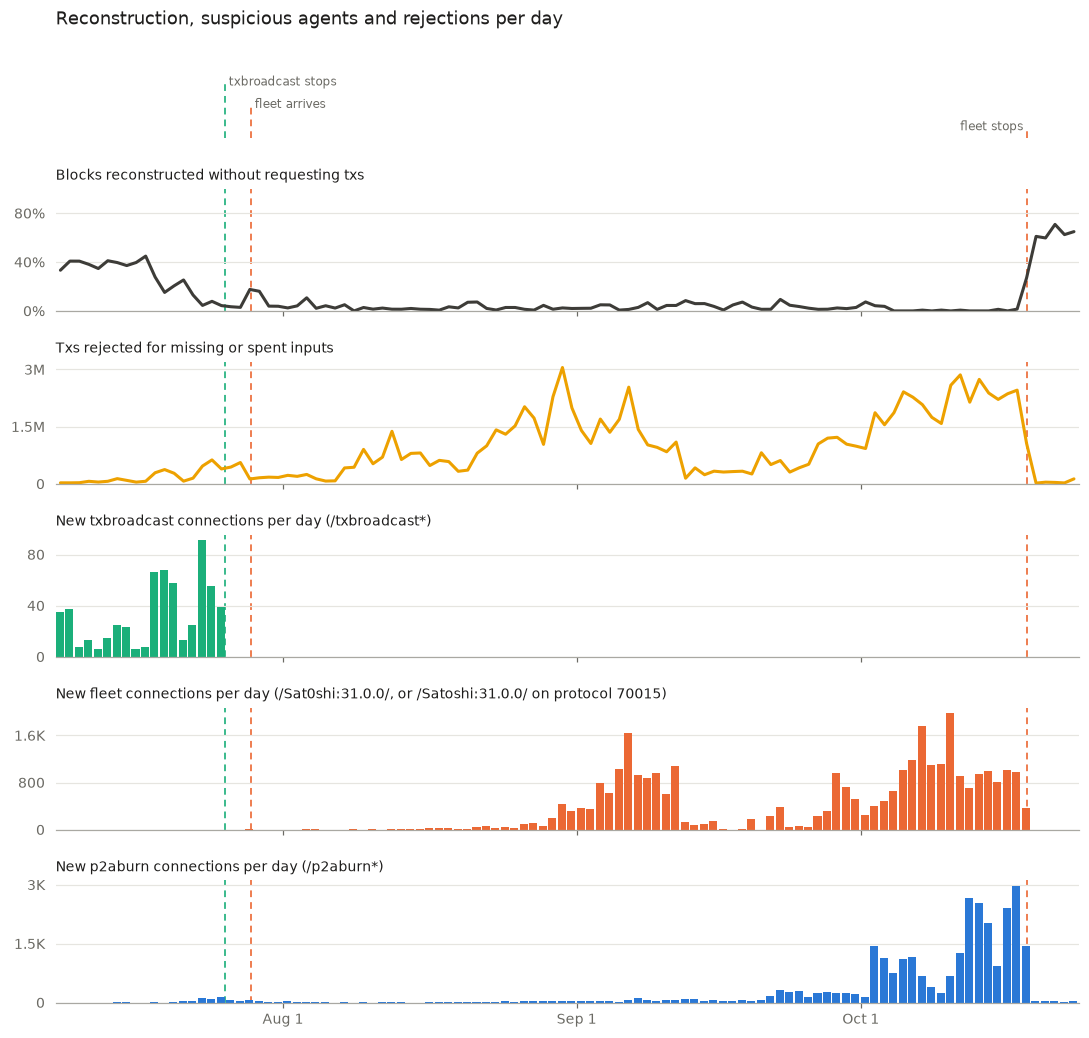

In [4]:
x0, x1 = panels.index.min(), panels.index.max() + ONE_DAY
noon = panels.index + ONE_DAY / 2  # a day's value is drawn at noon, over that day's bar
panel_specs = [
    ('Blocks reconstructed without requesting txs', 'line', 'reconstruction_no_request_share', COLORS['share']),
    ('Txs rejected for missing or spent inputs', 'line', 'rejected_inputs_missing', COLORS['missing']),
    ('New txbroadcast connections per day (/txbroadcast*)', 'bar', 'txbroadcast_new', COLORS['txbroadcast']),
    ('New fleet connections per day (/Sat0shi:31.0.0/, or /Satoshi:31.0.0/ on protocol 70015)', 'bar', 'fleet_new', COLORS['fleet']),
    ('New p2aburn connections per day (/p2aburn*)', 'bar', 'p2aburn_new', COLORS['p2aburn']),
]
fig, strip, axes = panel_figure(len(panel_specs), 11)
for ax, (title, kind, column, color) in zip(axes, panel_specs):
    series = panels[column]
    if kind == 'line':
        ax.plot(noon, series, color=color, lw=2, solid_joinstyle='round', solid_capstyle='round')
    else:
        series = series[series > 0]
        ax.bar(series.index, series, width=0.85, align='edge', color=color, lw=0)
    style_axis(ax, x0, x1, percent if column.endswith('share') else compact)
    ax.set_title(title)
axes[0].set_ylim(0, 1)
label_events(strip, x0, x1)
fig.suptitle('Reconstruction, suspicious agents and rejections per day', x=0.125, y=0.93, ha='left', fontsize=12, color=INK)
plt.show()

## 4. Messages received per day and peer group

The top panel repeats the reconstruction share from the first chart, on this chart's dates.

Solid: tx messages. Hatched on top (txbroadcast, p2aburn and fleet): every other message type. Other peers show tx
messages only, since most of their traffic is other types and would flatten their tx bars. Connections opened
before the first log have no user agent (`unknown`) until bitcoind restarts, and are drawn with other peers.

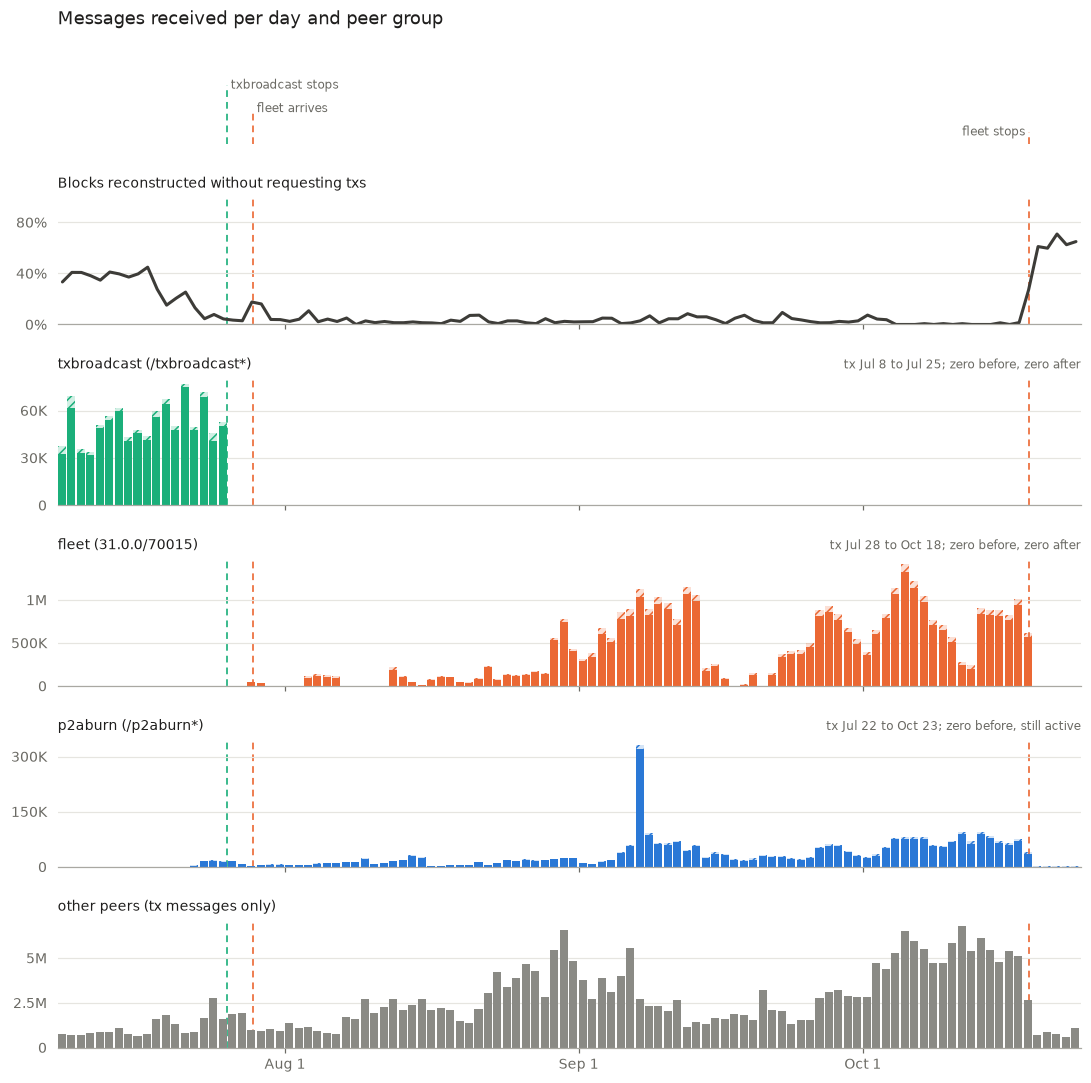

In [5]:
by_panel = msgs.assign(panel=msgs.group.replace({'unknown': 'other'}))
tx = by_panel.pivot_table(index='day', columns='panel', values='tx', aggfunc='sum').fillna(0)
all_msgs = by_panel.pivot_table(index='day', columns='panel', values='messages', aggfunc='sum').fillna(0)
x0, x1 = tx.index.min(), tx.index.max() + ONE_DAY
groups = ['txbroadcast', 'fleet', 'p2aburn', 'other']
fig, strip, axes = panel_figure(len(groups) + 1, 11.5)
share = panels['reconstruction_no_request_share']
axes[0].plot(share.index + ONE_DAY / 2, share, color=COLORS['share'], lw=2, solid_joinstyle='round', solid_capstyle='round')
style_axis(axes[0], x0, x1, percent)
axes[0].set_ylim(0, 1)
axes[0].set_title('Blocks reconstructed without requesting txs')
for ax, g in zip(axes[1:], groups):
    g_tx, g_all = tx[g], all_msgs[g]
    stacked = g != 'other'
    ax.bar(g_tx.index, g_tx, width=0.85, align='edge', color=COLORS[g], lw=0)
    if stacked:
        non_tx = (g_all - g_tx)[g_all > g_tx]
        ax.bar(non_tx.index, non_tx, bottom=g_tx[non_tx.index], width=0.85, align='edge', facecolor=COLORS[g] + '33',
               edgecolor=COLORS[g], hatch='////', lw=0)
    style_axis(ax, x0, x1)
    ax.set_title(LABELS[g] + ('' if stacked else ' (tx messages only)'))
    tx_days = g_tx[g_tx > 0]
    if stacked and len(tx_days):
        first, last = tx_days.index[0], tx_days.index[-1]
        after = 'still active' if last == g_tx.index[-1] else 'zero after'
        ax.set_title(f'tx {first:%b %-d} to {last:%b %-d}; zero before, {after}', loc='right', color=MUTED, fontsize=8)
label_events(strip, x0, x1)
fig.suptitle('Messages received per day and peer group', x=0.125, y=0.93, ha='left', fontsize=12, color=INK)
plt.show()